# English ↔ Arabic Neural Machine Translation

## 0. Project configuration

In [2]:
SEED = 42
DATASET_NAME = "ymoslem/UN-Arabic-English-Filtered"
N_TRAIN_PAIRS = 50_000

RUN_MARIAN_EN_AR = True
RUN_MARIAN_AR_EN = True
RUN_M2M100 = True

DEFAULT_DEPLOYMENT_MODEL = "marian_en_ar"   # marian_en_ar | marian_ar_en | m2m100
MAX_SOURCE_TOKENS = 128
MAX_TARGET_TOKENS = 128
TRAIN_EPOCHS = 10
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
LEARNING_RATE = 3e-5

ARTIFACT_ROOT = "./artifacts"

## 1. Imports

In [3]:
%pip install -q sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 2.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import re
import json
import random
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from datasets import load_dataset, Dataset
from transformers import (
    set_seed,
    MarianTokenizer,
    MarianMTModel,
    M2M100Tokenizer,
    M2M100ForConditionalGeneration,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
)
from sacrebleu.metrics import BLEU, CHRF, TER

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()
Path(ARTIFACT_ROOT).mkdir(parents=True, exist_ok=True)

print(f"Device: {DEVICE}")
print(f"CUDA available: {torch.cuda.is_available()}")


Device: cuda
CUDA available: True


## 2. Load the parallel corpus

In [5]:
ds = load_dataset(DATASET_NAME)
print(ds)
print("\nSplit sizes:")
print(pd.Series({split: len(ds[split]) for split in ds}))

N_TRAIN = min(N_TRAIN_PAIRS, len(ds["train"]))
train_raw = ds["train"].select(range(N_TRAIN))
dev_raw = ds["dev"]
test_raw = ds["test"]

print(f"\nSelected training pairs: {len(train_raw):,}")
print(f"Validation pairs: {len(dev_raw):,}")
print(f"Test pairs: {len(test_raw):,}")


README.md:   0%|          | 0.00/3.28k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

data/train-00000-of-00019.parquet: reconstructing file:   0%|          |  0.00B /  271MB            

data/train-00000-of-00019.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/19279407 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/8752 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/8752 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['text_en', 'text_ar'],
        num_rows: 19279407
    })
    test: Dataset({
        features: ['text_en', 'text_ar'],
        num_rows: 8752
    })
    dev: Dataset({
        features: ['text_en', 'text_ar'],
        num_rows: 8752
    })
})

Split sizes:
train    19279407
test         8752
dev          8752
dtype: int64

Selected training pairs: 50,000
Validation pairs: 8,752
Test pairs: 8,752


## 3. EDA

In [6]:
eda_df = train_raw.to_pandas().copy()

def safe_text(x):
    return x if isinstance(x, str) else ""

def word_count(text):
    return len(re.findall(r"\S+", safe_text(text).strip()))

def char_count(text):
    return len(safe_text(text).strip())

In [7]:
eda_df["en_words"] = eda_df["text_en"].map(word_count)
eda_df["ar_words"] = eda_df["text_ar"].map(word_count)
eda_df["en_chars"] = eda_df["text_en"].map(char_count)
eda_df["ar_chars"] = eda_df["text_ar"].map(char_count)

In [8]:
quality = pd.DataFrame({
    "english_null_or_empty": [int((eda_df["text_en"].fillna("").str.strip() == "").sum())],
    "arabic_null_or_empty": [int((eda_df["text_ar"].fillna("").str.strip() == "").sum())],
    "duplicate_pairs": [int(eda_df.duplicated(["text_en", "text_ar"]).sum())],
    "english_avg_words": [eda_df["en_words"].mean()],
    "arabic_avg_words": [eda_df["ar_words"].mean()],
})

In [9]:
display(quality.round(2))

,english_null_or_empty,arabic_null_or_empty,duplicate_pairs,english_avg_words,arabic_avg_words
0,0,0,0,28.46,25.12


In [10]:
display(eda_df[["text_en", "text_ar"]].head(10))

,text_en,text_ar
0,C. Available methods and tools for planning,جيم- الأساليب والأدوات المتاحة للتخطيط
1,"Nevertheless, it is my opinion that the Specia...",ومع ذلك فإني أرى أن المقرر الخاص المعني بمسألة...
2,"21. The CHAIRMAN announced that Angola, Cape V...",١٢ - الرئيس: أعلن أن كﻻ من المانيا وأنغوﻻ وبنم...
3,Decides to allocate in the 2012 - 2013 program...,57 - يقرر أن يرصد في الميزانية البرنامجية للفت...
4,"Also in February, Russian retail trade decline...",وفي شهر شباط/فبراير أيضا، انخفضت تجارة التجزئة...
5,"Vu Anh Binh Tran, born in 1974; a songwriter a...",فو آنه بينه تران، مولود في عام 1974، وكاتب أغا...
6,b. Parliamentary documentation: consolidated r...,ب - وثائق الهيئات التداولية: القرار الموحد بشأ...
7,Morocco noted the emergence of a new pattern o...,ولاحظ المغرب ظهور نمط جديد في الاتّجار بالقنّب...
8,The conference is organized by ICIMOD and the ...,ويتولى المركز المذكور ومنتدى الجبال تنظيم هذا ...
9,107. Congress may delegate to the Executive th...,٧٠١- يجوز للجمعية التأسيسية أن تفوض الهيئة الت...


### 3.1 Sentence-length distributions

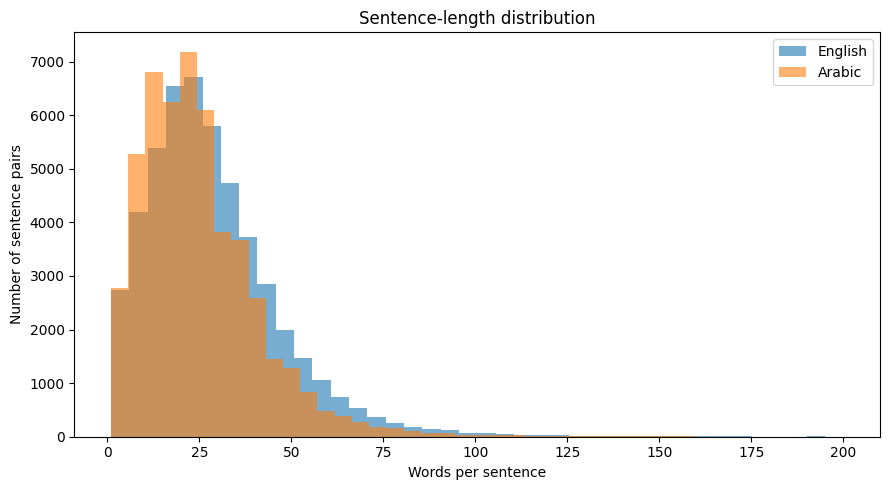

In [11]:
plt.figure(figsize=(9, 5))
plt.hist(eda_df["en_words"], bins=40, alpha=0.6, label="English")
plt.hist(eda_df["ar_words"], bins=40, alpha=0.6, label="Arabic")
plt.xlabel("Words per sentence")
plt.ylabel("Number of sentence pairs")
plt.title("Sentence-length distribution")
plt.legend()
plt.tight_layout()
plt.show()


### 3.2 English vs. Arabic sentence length relationship

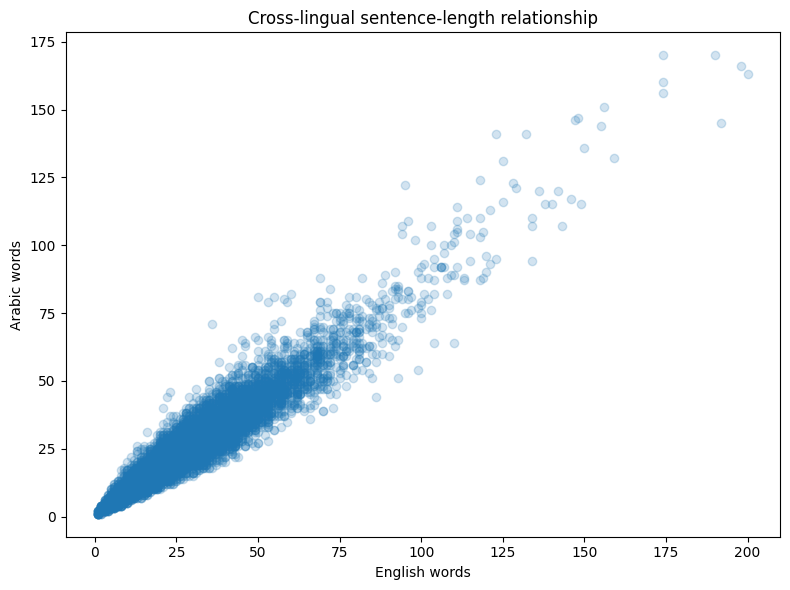

In [12]:
plot_df = eda_df.sample(min(10_000, len(eda_df)), random_state=SEED)
plt.figure(figsize=(8, 6))
plt.scatter(plot_df["en_words"], plot_df["ar_words"], alpha=0.2)
plt.xlabel("English words")
plt.ylabel("Arabic words")
plt.title("Cross-lingual sentence-length relationship")
plt.tight_layout()
plt.show()


### 3.3 Target/source length ratio

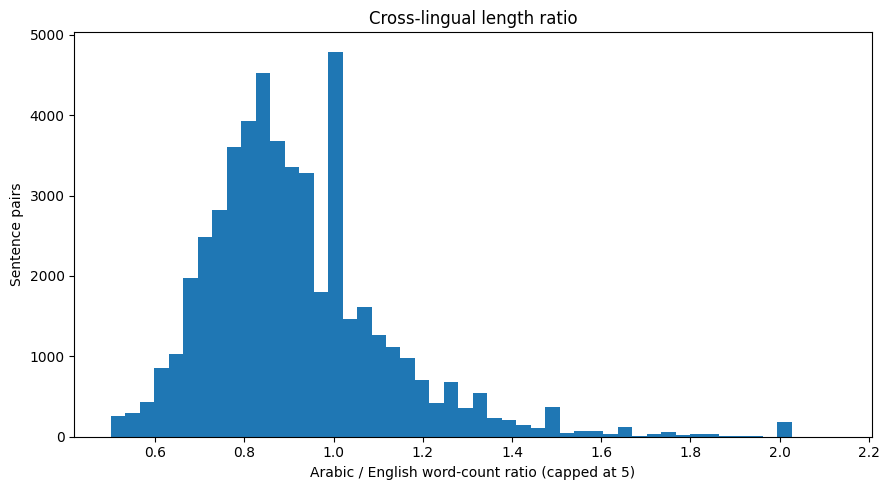

count    50000.00
mean         0.92
std          0.21
min          0.50
25%          0.78
50%          0.88
75%          1.00
max          2.12
Name: ar_to_en_ratio, dtype: float64


In [13]:
ratio_df = eda_df[(eda_df["en_words"] > 0) & (eda_df["ar_words"] > 0)].copy()
ratio_df["ar_to_en_ratio"] = ratio_df["ar_words"] / ratio_df["en_words"]

plt.figure(figsize=(9, 5))
plt.hist(ratio_df["ar_to_en_ratio"].clip(upper=5), bins=50)
plt.xlabel("Arabic / English word-count ratio (capped at 5)")
plt.ylabel("Sentence pairs")
plt.title("Cross-lingual length ratio")
plt.tight_layout()
plt.show()

print(ratio_df["ar_to_en_ratio"].describe().round(2))


### 3.4 Frequent-token inspection

In [14]:
ARABIC_DIACRITICS_RE = re.compile(r"[\u0617-\u061A\u064B-\u0652]")
TOKEN_RE = re.compile(r"[\w\u0600-\u06FF]+", flags=re.UNICODE)

def simple_tokens(text):
    return TOKEN_RE.findall(safe_text(text).lower())

,token,count
0,the,126032
1,of,74454
2,and,55127
3,to,44410
4,in,35587
5,a,19978
6,for,17830
7,on,16134
8,that,14913
9,by,10131


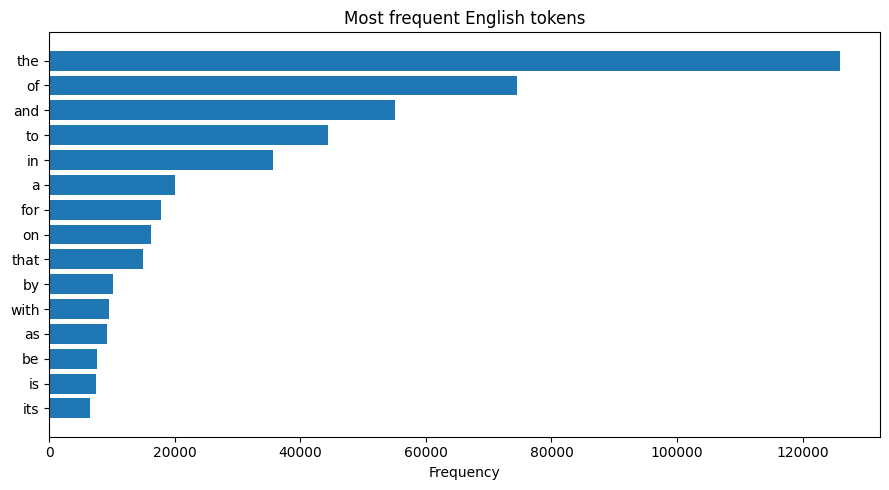

,token,count
0,في,47013
1,من,29194
2,على,19250
3,إلى,13911
4,أن,13313
5,التي,9673
6,عن,7832
7,المتحدة,6458
8,أو,5539
9,الأمم,4295


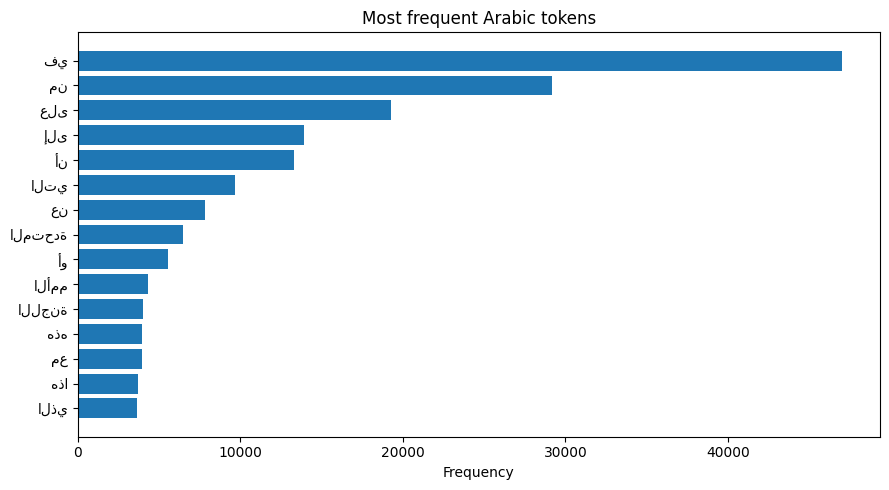

In [15]:
for lang, col in [("English", "text_en"), ("Arabic", "text_ar")]:
    counts = Counter(tok for text in eda_df[col] for tok in simple_tokens(text))
    top = pd.DataFrame(counts.most_common(15), columns=["token", "count"])
    display(top.style.set_caption(f"Top {lang} tokens"))
    plt.figure(figsize=(9, 5))
    plt.barh(top["token"][::-1], top["count"][::-1])
    plt.title(f"Most frequent {lang} tokens")
    plt.xlabel("Frequency")
    plt.tight_layout()
    plt.show()

### 3.5 Qualitative corpus sample

In [16]:
display(eda_df[["text_en", "text_ar"]].sample(12, random_state=SEED).reset_index(drop=True))

,text_en,text_ar
0,The Chairman recommended that the Credentials ...,8 - وأوصى الرئيس بأن تقبل لجنة وثائق التفويض و...
1,"To date, the Commission has received no respon...",وحتى تاريخه لم تتلق اللجنة أي رد على هذا الطلب.
2,"In that decision, the Conference of the Partie...",وفي هذا المقرر، رحب مؤتمر الأطراف بالدعوة التي...
3,Harmonize principles and methods for risk asse...,توحيد مبادئ وطرق تقييم المخاطر ، (مثل، الطرق ا...
4,The international community should abide by th...,وعلى المجتمع الدولي أن يفي بمقاصد ومبادئ ميثاق...
5,(c) To disarm the Janjaweed militias and stop ...,(ج) نزع سلاح ميليشيات الجنجويد، والتوقف عن دعم...
6,Bearing in mind that one of the fundamental pu...,إذ يضع في اعتباره أن واحدا من الأغراض الأساسية...
7,20. Of key importance to UNDP and partners is ...,20 - ومن الأمور التي لها أهمية رئيسية بالنسبة ...
8,9. Decides to suspend for the immediate future...,9 - تقـرر تعليق العمل في المستقبل الفوري بأحكا...
9,Document: Report of the Secretary-General (res...,الوثيقة: تقرير اﻷمين العام )القرار ٤٧/١٦١(، A/...


## 4. Conservative bilingual normalization

In [17]:

def clean_pairs(dataset):
    dataset = dataset.filter(
        lambda x: bool(x["text_en"].strip())
        and bool(x["text_ar"].strip())
    )

    pdf = (
        dataset.to_pandas()
        .drop_duplicates(subset=["text_en", "text_ar"])
        .reset_index(drop=True)
    )

    return Dataset.from_pandas(pdf, preserve_index=False)


# Clean the original dataset splits
train_clean = clean_pairs(train_raw)
dev_clean = clean_pairs(dev_raw)
test_clean = clean_pairs(test_raw)

print({
    "train": len(train_clean),
    "dev": len(dev_clean),
    "test": len(test_clean)
})

Filter:   0%|          | 0/50000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8752 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8752 [00:00<?, ? examples/s]

{'train': 50000, 'dev': 8752, 'test': 8752}


In [18]:
# Normalization impact on a small visual sample
impact = pd.DataFrame({
    "English chars before": train_raw.to_pandas()["text_en"].head(1000).fillna("").map(len),
    "English chars after": train_clean.to_pandas()["text_en"].head(min(1000, len(train_clean))).fillna("").map(len),
})
display(pd.DataFrame({
    "metric": ["English mean chars", "Arabic mean chars"],
    "before": [train_raw.to_pandas()["text_en"].fillna("").map(len).mean(), train_raw.to_pandas()["text_ar"].fillna("").map(len).mean()],
    "after": [train_clean.to_pandas()["text_en"].map(len).mean(), train_clean.to_pandas()["text_ar"].map(len).mean()],
}).round(2))


,metric,before,after
0,English mean chars,185.42,185.42
1,Arabic mean chars,154.91,154.91


## 5. Translation experiment framework

In [19]:
EXPERIMENTS = {
    "marian_en_ar": {
        "model_name": "Helsinki-NLP/opus-mt-en-ar",
        "src_col": "text_en", "tgt_col": "text_ar",
        "src_lang": "en", "tgt_lang": "ar",
        "bleu_tokenize": "none",
        "output_dir": f"{ARTIFACT_ROOT}/marian_en_ar",
        "run": RUN_MARIAN_EN_AR,
    },
    "marian_ar_en": {
        "model_name": "Helsinki-NLP/opus-mt-ar-en",
        "src_col": "text_ar", "tgt_col": "text_en",
        "src_lang": "ar", "tgt_lang": "en",
        "bleu_tokenize": "13a",
        "output_dir": f"{ARTIFACT_ROOT}/marian_ar_en",
        "run": RUN_MARIAN_AR_EN,
    },
}

results = {}


### 5.1 Tokenization helper

In [20]:
def build_tokenized_dataset(tokenizer, src_col, tgt_col, is_m2m100=False, src_lang="en", tgt_lang="ar"):
    def preprocess(batch):
        sources = batch[src_col]
        targets = batch[tgt_col]
        if is_m2m100:
            tokenizer.src_lang = src_lang
            model_inputs = tokenizer(sources, max_length=MAX_SOURCE_TOKENS, truncation=True)
            with tokenizer.as_target_tokenizer():
                labels = tokenizer(targets, max_length=MAX_TARGET_TOKENS, truncation=True)
        else:
            model_inputs = tokenizer(sources, max_length=MAX_SOURCE_TOKENS, truncation=True)
            labels = tokenizer(text_target=targets, max_length=MAX_TARGET_TOKENS, truncation=True)
        model_inputs["labels"] = labels["input_ids"]
        return model_inputs

    tokenized_train = train_clean.map(preprocess, batched=True, remove_columns=train_clean.column_names)
    tokenized_dev = dev_clean.map(preprocess, batched=True, remove_columns=dev_clean.column_names)
    tokenized_test = test_clean.map(preprocess, batched=True, remove_columns=test_clean.column_names)
    return tokenized_train, tokenized_dev, tokenized_test


### 5.2 Metrics helper

In [21]:
def make_compute_metrics(tokenizer, bleu_tokenize):
    bleu_metric = BLEU(tokenize=bleu_tokenize)
    chrf_metric = CHRF()
    ter_metric = TER()

    def compute_metrics(pred):
        predictions = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
        labels = np.where(pred.label_ids != -100, pred.label_ids, tokenizer.pad_token_id)
        decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
        decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
        decoded_preds = [x.strip() for x in decoded_preds]
        decoded_labels = [x.strip() for x in decoded_labels]
        return {
            "bleu": bleu_metric.corpus_score(decoded_preds, [decoded_labels]).score,
            "chrf": chrf_metric.corpus_score(decoded_preds, [decoded_labels]).score,
            "ter": ter_metric.corpus_score(decoded_preds, [decoded_labels]).score,
        }
    return compute_metrics


### 5.3 Train/evaluate a MarianMT experiment

In [22]:
def run_marian_experiment(key):
    cfg = EXPERIMENTS[key]
    tokenizer = MarianTokenizer.from_pretrained(cfg["model_name"])
    model = MarianMTModel.from_pretrained(cfg["model_name"])

    tokenized_train, tokenized_dev, tokenized_test = build_tokenized_dataset(
        tokenizer, cfg["src_col"], cfg["tgt_col"], is_m2m100=False,
        src_lang=cfg["src_lang"], tgt_lang=cfg["tgt_lang"]
    )

    collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)
    args = Seq2SeqTrainingArguments(
        output_dir=cfg["output_dir"],
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        weight_decay=0.01,
        num_train_epochs=TRAIN_EPOCHS,
        predict_with_generate=True,
        fp16=USE_FP16,
        logging_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=True,
        report_to="none",
    )

    trainer = Seq2SeqTrainer(
        model=model, args=args,
        train_dataset=tokenized_train, eval_dataset=tokenized_dev,
        processing_class=tokenizer, data_collator=collator,
        compute_metrics=make_compute_metrics(tokenizer, cfg["bleu_tokenize"]),
    )

    train_result = trainer.train()
    test_output = trainer.predict(tokenized_test, metric_key_prefix="test")
    metrics = {k: float(v) for k, v in test_output.metrics.items() if isinstance(v, (int, float, np.floating))}

    final_dir = os.path.join(cfg["output_dir"], "final_model")
    trainer.save_model(final_dir)
    tokenizer.save_pretrained(final_dir)
    with open(os.path.join(cfg["output_dir"], "test_metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    history = pd.DataFrame(trainer.state.log_history)
    return {"trainer": trainer, "tokenizer": tokenizer, "model": trainer.model, "metrics": metrics, "history": history, "final_dir": final_dir}


In [23]:
EXPERIMENTS["marian_en_ar"]["run"] = RUN_MARIAN_EN_AR
EXPERIMENTS["marian_ar_en"]["run"] = RUN_MARIAN_AR_EN

marian_outputs = {}
for key in ["marian_en_ar", "marian_ar_en"]:
    if EXPERIMENTS[key]["run"]:
        print(f"\nRunning {key}...")
        marian_outputs[key] = run_marian_experiment(key)
        print(marian_outputs[key]["metrics"])
    else:
        print(f"Skipped {key} (RUN flag is False).")



Running marian_en_ar...


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/917k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.12M [00:00<?, ?B/s]

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.encoder.embed_positions.weight', 'model.decoder.embed_tokens.weight', 'model.decoder.embed_positions.weight', 'lm_head.weight'].
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'test_loss': 0.5302987694740295, 'test_bleu': 65.33852663341861, 'test_chrf': 81.4380913764253, 'test_ter': 26.709452678101275, 'test_runtime': 626.3012, 'test_samples_per_second': 13.974, 'test_steps_per_second': 0.873}


### 5.4 M2M100 bidirectional experiment (optional)

M2M100 is kept as the multilingual/bidirectional comparison model. It uses the same 50k training pairs, expanded into both translation directions.

## 6. Training diagnostics

When a training run is enabled, inspect training vs. validation loss before trusting the final metrics.

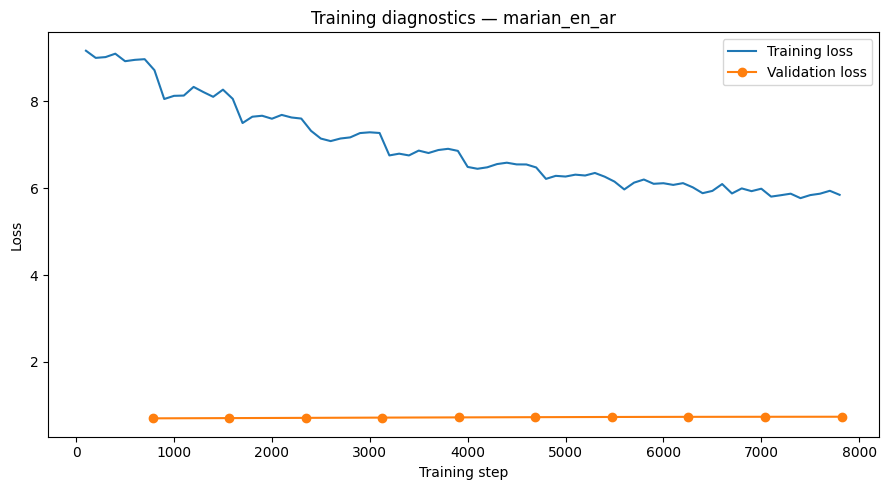

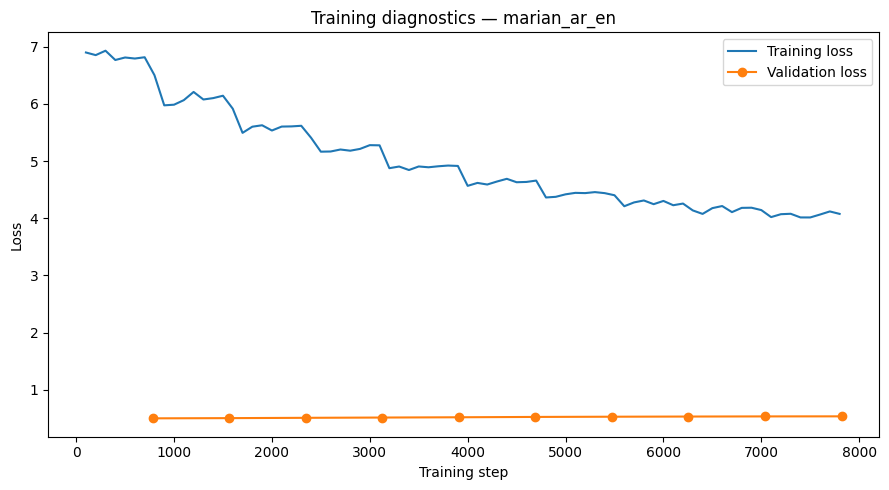

In [48]:
def plot_training_history(output, title):
    history = output["history"]
    train_log = history[history.get("loss", pd.Series(index=history.index)).notna()] if "loss" in history else pd.DataFrame()
    eval_log = history[history.get("eval_loss", pd.Series(index=history.index)).notna()] if "eval_loss" in history else pd.DataFrame()

    plt.figure(figsize=(9, 5))
    if not train_log.empty:
        plt.plot(train_log["step"], train_log["loss"], label="Training loss")
    if not eval_log.empty:
        plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="Validation loss")
    plt.title(title)
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

for key, output in marian_outputs.items():
    plot_training_history(output, f"Training diagnostics — {key}")


## 7. Compare available test metrics

In [49]:
comparison_rows = []
for key, output in marian_outputs.items():
    row = {"experiment": key}
    row.update(output["metrics"])
    comparison_rows.append(row)

In [50]:
if comparison_rows:
    comparison_df = pd.DataFrame(comparison_rows).sort_values("test_bleu", ascending=False)
    display(comparison_df.round(3))
else:
    print("No trained MarianMT experiments available yet. Set a RUN_* flag to True and execute the training section.")

,experiment,test_loss,test_bleu,test_chrf,test_ter,test_runtime,test_samples_per_second,test_steps_per_second
1,marian_ar_en,0.53,65.339,81.438,26.709,626.301,13.974,0.873
0,marian_en_ar,0.74,46.105,75.459,38.386,518.442,16.881,1.055


## 8. Qualitative evaluation and lightweight error analysis

In [53]:
if marian_outputs:
    test_df = test_clean.to_pandas()

    for key, output in marian_outputs.items():
        cfg = EXPERIMENTS[key]

        sample = (
            test_df[[cfg["src_col"], cfg["tgt_col"]]]
            .sample(min(20, len(test_df)), random_state=SEED)
            .reset_index(drop=True)
        )

        # Use the trained Marian model directly
        model = output["model"]
        tokenizer = output["tokenizer"]

        device = next(model.parameters()).device
        model.eval()

        inputs = tokenizer(
            sample[cfg["src_col"]].tolist(),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SOURCE_TOKENS
        ).to(device)

        with torch.no_grad():
            generated_ids = model.generate(
                **inputs,
                max_length=MAX_TARGET_TOKENS
            )

        predictions = tokenizer.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        sample["prediction"] = predictions

        sentence_metric = BLEU(tokenize=cfg["bleu_tokenize"])

        sample["sentence_bleu"] = [
            sentence_metric.sentence_score(pred, [ref]).score
            for pred, ref in zip(
                sample["prediction"],
                sample[cfg["tgt_col"]]
            )
        ]

        print(
            f"\n{key} — 5 lowest-scoring examples "
            f"from 20 test examples"
        )

        display(
            sample
            .sort_values("sentence_bleu")
            .head(5)
            .reset_index(drop=True)
        )

It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is 


marian_en_ar — 5 lowest-scoring examples from 20 test examples


,text_en,text_ar,prediction,sentence_bleu
0,"a) credit institutions,",(أ) المؤسسات الائتمانية،,(أ) المؤسسات الائتمانية،,0.000000
1,26. But technical cooperation also proved ulti...,26 - غير أنه اتضح في نهاية الأمر أن التعاون ال...,٢٦ - غير أن التعاون التقني أثبت أيضا أنه في نه...,10.534468
2,"Geneva was not included in this review, as it ...",ولم يشمل الاستعراض جنيف، التي تناولتها تقارير ...,ولم تدرج جنيف في هذا الاستعراض، لأنه جرى تناول...,16.617429
3,"To achieve this, the international community m...",ولتحقيق ذلك، يتعين على المجتمع الدولي دعم هذه ...,ولتحقيق ذلك، يجب على المجتمع الدولي أن يدعم هذ...,22.547685
4,The Board recommended that the Office of Inter...,ويوصى المجلس بأن يعجّل مكتب خدمات الرقابة الدا...,وأوصى المجلس مكتب خدمات الرقابة الداخلية بالتع...,23.214604


It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is recommended to enable `effective_order` for sentence-level BLEU.
It is 


marian_ar_en — 5 lowest-scoring examples from 20 test examples


,text_ar,text_en,prediction,sentence_bleu
0,26 - غير أنه اتضح في نهاية الأمر أن التعاون ال...,26. But technical cooperation also proved ulti...,"26. Finally, however, it has become clear that...",8.301095
1,وفيما يتعلق بالخدمات، قد تُطلب أيضاً، في المفا...,"As regards services, commitments would also be...","With respect to services, in bilateral negotia...",14.670971
2,(أ) المؤسسات الائتمانية،,"a) credit institutions,","(a) Credit institutions,",22.957488
3,ولم يشمل الاستعراض جنيف، التي تناولتها تقارير ...,"Geneva was not included in this review, as it ...","The review did not include Geneva, which had b...",23.185527
4,ويوصى المجلس بأن يعجّل مكتب خدمات الرقابة الدا...,The Board recommended that the Office of Inter...,The Board recommends that OIOS expedite the fi...,36.644628


## 9. Reusable inference layer

In [54]:
class TranslationService:
    def __init__(self, model_path, model_type="marian", src_lang="en", tgt_lang="ar"):
        self.model_type = model_type
        self.src_lang = src_lang
        self.tgt_lang = tgt_lang
        if model_type == "marian":
            self.tokenizer = MarianTokenizer.from_pretrained(model_path)
            self.model = MarianMTModel.from_pretrained(model_path).to(DEVICE)
        elif model_type == "m2m100":
            self.tokenizer = M2M100Tokenizer.from_pretrained(model_path)
            self.model = M2M100ForConditionalGeneration.from_pretrained(model_path).to(DEVICE)
        else:
            raise ValueError("model_type must be 'marian' or 'm2m100'")
        self.model.eval()

    @torch.inference_mode()
    def translate(self, text):
        if not isinstance(text, str) or not text.strip():
            return ""
        if self.model_type == "marian":
            inputs = self.tokenizer([text], return_tensors="pt", truncation=True, max_length=MAX_SOURCE_TOKENS).to(DEVICE)
            generated = self.model.generate(**inputs, max_length=MAX_TARGET_TOKENS, num_beams=4)
            return self.tokenizer.decode(generated[0], skip_special_tokens=True)

        self.tokenizer.src_lang = self.src_lang
        encoded = self.tokenizer([text], return_tensors="pt", truncation=True, max_length=MAX_SOURCE_TOKENS).to(DEVICE)
        forced_bos = self.tokenizer.get_lang_id(self.tgt_lang)
        generated = self.model.generate(**encoded, forced_bos_token_id=forced_bos, max_length=MAX_TARGET_TOKENS, num_beams=4)
        return self.tokenizer.batch_decode(generated, skip_special_tokens=True)[0]


## 10. Gradio

In [57]:
LAUNCH_GUI = True

if LAUNCH_GUI:
    import gradio as gr

    # Load both Marian models
    en_ar_path = f"{ARTIFACT_ROOT}/marian_en_ar/final_model"
    ar_en_path = f"{ARTIFACT_ROOT}/marian_ar_en/final_model"

    en_ar_service = TranslationService(
        en_ar_path,
        model_type="marian",
        src_lang="en",
        tgt_lang="ar"
    )

    ar_en_service = TranslationService(
        ar_en_path,
        model_type="marian",
        src_lang="ar",
        tgt_lang="en"
    )

    def translate_text(text, direction):
        if not text or not text.strip():
            return ""

        if direction == "English → Arabic":
            return en_ar_service.translate(text)

        elif direction == "Arabic → English":
            return ar_en_service.translate(text)

        return ""

    demo = gr.Interface(
        fn=translate_text,

        inputs=[
            gr.Textbox(
                lines=6,
                label="Source Text",
                placeholder="Enter English or Arabic text..."
            ),

            gr.Radio(
                choices=[
                    "English → Arabic",
                    "Arabic → English"
                ],
                value="English → Arabic",
                label="Translation Direction"
            )
        ],

        outputs=gr.Textbox(
            lines=6,
            label="Translation"
        ),

        title="🌍 English ↔ Arabic Neural Machine Translation",

        description=(
            "Bidirectional Neural Machine Translation demo "
            "powered by two fine-tuned MarianMT Transformer models."
        )
    )

    demo.launch()

else:
    print(
        "GUI is prepared but not launched. "
        "Set LAUNCH_GUI=True after both model artifacts exist."
    )

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7861
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://917c96fdceea623eff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
